# 

# Stage B: subject-dependent, 10 contiguous folds per participant
One model per participant and fold (seed 42, lr from Stage A). Results go to `features_hifigan\stageB\`. Training runs as a detached background process; this notebook only launches and reads.

In [1]:
import os, sys, subprocess
ROOT = r"C:\seeg_v2"; os.chdir(ROOT); sys.path.insert(0, ROOT)
os.environ["SEEG_OUT_DIR"] = os.path.join(ROOT, "features_hifigan")
print([f for f in ["stageB_subject.py","stageA_pooled.py","stageA_extra.py","template_floor_continuous.py","stageB_verwoert_linear.py"] if not os.path.exists(f)] or "all files present")

all files present


## 1) Smoke test (a few minutes): checks the plumbing and prints the time per epoch

In [2]:
r = subprocess.run([sys.executable, "stageB_subject.py", "smoke", "run", "hybrid"], capture_output=True, text=True)
print(r.stdout[-2500:]); print(r.stderr[-1500:])

=== stage B | hybrid | lr 0.0003 | participants ['sub-02', 'sub-06'] | folds [0, 1]
finished participant-folds per model (100 = complete):
 model
hybrid    4
           pcc  template_pcc  residual_pcc  pcc_in_speech  template_in_speech
subject                                                                      
sub-02   0.646         0.734         0.181          0.166               0.309
sub-06   0.838         0.769         0.458          0.321               0.244




## 2) Launch models in the background (resumable: finished folds are skipped)
Start with `linear` (quick). Neural models need their Stage-A learning rate, i.e. the Stage A run of that model must be finished.

In [12]:
MODELS = ["neuroincept"]                 # done: linear, baseline, hybrid.  next: "convedsr", then "neuroincept"
LR_OVERRIDE = {"neuroincept": "1e-4"}                       # leave empty = Stage-A lr.  For NeuroIncept (declared in advance): {"neuroincept": "1e-4"}
THREADS = ""                           # e.g. "4" to leave CPU for other jobs; "" = all
bat = os.path.join(ROOT, "run_stageB.bat")
lines = ["@echo off", f"cd /d {ROOT}", f"set SEEG_OUT_DIR={os.environ['SEEG_OUT_DIR']}"]
if THREADS: lines.append(f"set STAGEB_THREADS={THREADS}")
for _m, _lr in LR_OVERRIDE.items(): lines.append(f"set STAGEB_LR_{_m.upper()}={_lr}")
lines += [f'"{sys.executable}" stageB_subject.py run {m}' for m in MODELS]
open(bat, "w").write("\n".join(lines) + "\n")
subprocess.Popen(["cmd", "/c", bat], creationflags=0x00000008 | 0x00000200, close_fds=True)
print("started:", MODELS)

started: ['neuroincept']


## 3) Progress

In [15]:
import glob
d = os.path.join(os.environ["SEEG_OUT_DIR"], "stageB")
for m in ["linear","hybrid","baseline","neuroincept","convedsr"]:
    n = len(glob.glob(os.path.join(d, f"{m}_sub-*_fold*.json")))
    print(f"{m:12s} {n:3d}/100 participant-folds")
for lg in sorted(glob.glob(os.path.join(d, "log_*.txt"))):
    print("\n--", os.path.basename(lg)); print("".join(open(lg, errors="replace").readlines()[-3:]))

linear       100/100 participant-folds
hybrid       100/100 participant-folds
baseline     100/100 participant-folds
neuroincept  100/100 participant-folds
convedsr     100/100 participant-folds

-- log_baseline.txt
  sub-10 fold 9: [baseline lr=0.0001 seed=42] epoch 17/60: train loss 0.2785 | val MSE 0.6950 | 7s
  sub-10 fold 9: [baseline lr=0.0001 seed=42] epoch 18/60: train loss 0.2766 | val MSE 0.6986 | 7s
baseline_sub-10_fold9: PCC 0.619 | template 0.629 | in speech 0.326 (template 0.112) | residual +0.428 | 122s


-- log_convedsr.txt
  sub-10 fold 9: [convedsr lr=0.001 seed=42] epoch 14/60: train loss 1.2893 | val MSE 0.7764 | 14s
  sub-10 fold 9: [convedsr lr=0.001 seed=42] epoch 15/60: train loss 1.3131 | val MSE 0.8139 | 13s
convedsr_sub-10_fold9: PCC 0.514 | template 0.629 | in speech 0.238 (template 0.112) | residual +0.367 | 194s


-- log_hybrid.txt
  sub-10 fold 9: [hybrid lr=0.0001 seed=42] epoch 10/60: train loss 0.1952 | val MSE 0.7496 | 16s
  sub-10 fold 9: [hybrid lr=

## 4) Results (finished folds only; per participant = mean over its 10 folds)

In [16]:
import importlib, pandas as pd, stageB_subject as B, stageA_report as R
importlib.reload(B); importlib.reload(R); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
R.LABEL["linear"] = "Linear (Verwoert-style, per participant)"       # Stage B is subject-dependent
dfb = B.load_runs_b()
print(dfb.groupby("model")["fold"].count().rename("participant-folds"))
R.model_table(dfb)

model
baseline       100
convedsr       100
hybrid         100
linear         100
neuroincept    100
Name: participant-folds, dtype: int64


,seeds,lr,PCC,template PCC,PCC − template,PCC in speech,template in speech,in speech − template,residual PCC
model,,,,,,,,,
"Linear (Verwoert-style, per participant)",1,NaN,+0.675,+0.714,-0.038,+0.248,+0.214,+0.035,+0.351
Baseline CNN-BiLSTM,1,0.0001,+0.754,+0.714,+0.040,+0.270,+0.214,+0.056,+0.475
Hybrid (MR-ResBlocks),1,0.0001,+0.752,+0.714,+0.039,+0.300,+0.214,+0.087,+0.477
NeuroIncept (re-impl.),1,0.0001,+0.556,+0.714,-0.157,+0.191,+0.214,-0.023,+0.340
ConvED-SR-style (re-impl.),1,0.0010,+0.623,+0.714,-0.091,+0.193,+0.214,-0.020,+0.321


In [17]:
R.subject_table(dfb, "pcc")

,"Linear (Verwoert-style, per participant)",Baseline CNN-BiLSTM,Hybrid (MR-ResBlocks),NeuroIncept (re-impl.),ConvED-SR-style (re-impl.),Template (no neural input)
subject,,,,,,
sub-01,0.510,0.672,0.687,0.003,0.424,0.715
sub-02,0.621,0.688,0.699,0.655,0.534,0.728
sub-03,0.811,0.836,0.842,0.350,0.772,0.655
sub-04,0.768,0.828,0.838,0.810,0.694,0.771
sub-05,0.520,0.605,0.598,0.423,0.434,0.749
sub-06,0.840,0.867,0.867,0.868,0.842,0.801
sub-07,0.685,0.782,0.777,0.751,0.657,0.588
sub-08,0.702,0.758,0.742,0.724,0.620,0.790
sub-09,0.641,0.788,0.772,0.290,0.643,0.750


In [18]:
R.subject_table(dfb, "pcc_in_speech")

,"Linear (Verwoert-style, per participant)",Baseline CNN-BiLSTM,Hybrid (MR-ResBlocks),NeuroIncept (re-impl.),ConvED-SR-style (re-impl.),Template (no neural input)
subject,,,,,,
sub-01,0.201,0.222,0.288,0.001,0.146,0.189
sub-02,0.175,0.165,0.195,0.158,0.121,0.210
sub-03,0.352,0.354,0.402,0.138,0.303,0.227
sub-04,0.280,0.319,0.368,0.293,0.193,0.230
sub-05,0.139,0.168,0.146,0.127,0.096,0.208
sub-06,0.340,0.365,0.385,0.358,0.339,0.277
sub-07,0.311,0.329,0.351,0.300,0.214,0.161
sub-08,0.257,0.222,0.250,0.210,0.180,0.261
sub-09,0.144,0.255,0.279,0.067,0.090,0.222


In [19]:
R.subject_table(dfb, "residual_pcc")

,"Linear (Verwoert-style, per participant)",Baseline CNN-BiLSTM,Hybrid (MR-ResBlocks),NeuroIncept (re-impl.),ConvED-SR-style (re-impl.)
subject,,,,,
sub-01,0.153,0.340,0.363,0.003,0.144
sub-02,0.241,0.346,0.360,0.298,0.185
sub-03,0.617,0.679,0.691,0.267,0.543
sub-04,0.398,0.521,0.544,0.484,0.326
sub-05,0.197,0.291,0.305,0.197,0.161
sub-06,0.481,0.569,0.561,0.569,0.503
sub-07,0.510,0.653,0.646,0.605,0.478
sub-08,0.297,0.372,0.366,0.342,0.250
sub-09,0.179,0.445,0.414,0.145,0.221


In [20]:
R.paired_table(dfb, [("hybrid","linear"), ("hybrid","baseline"), ("hybrid","neuroincept"), ("hybrid","convedsr"),
                    ("baseline","linear"), ("neuroincept","linear"), ("convedsr","linear")])

,comparison,metric,n,mean_diff,a_better_in,p_exact_two_sided
0,Hybrid (MR-ResBlocks) minus Linear (Verwoert...,pcc,10,0.0771,10/10,0.0020
1,Hybrid (MR-ResBlocks) minus Linear (Verwoert...,pcc_in_speech,10,0.0521,9/10,0.0039
2,Hybrid (MR-ResBlocks) minus Linear (Verwoert...,residual_pcc,10,0.1267,10/10,0.0020
3,Hybrid (MR-ResBlocks) minus Baseline CNN-BiLSTM,pcc,10,-0.0015,4/10,0.6250
4,Hybrid (MR-ResBlocks) minus Baseline CNN-BiLSTM,pcc_in_speech,10,0.0302,9/10,0.0059
5,Hybrid (MR-ResBlocks) minus Baseline CNN-BiLSTM,residual_pcc,10,0.0027,5/10,0.4922
6,Hybrid (MR-ResBlocks) minus NeuroIncept (re-...,pcc,10,0.1961,9/10,0.0039
7,Hybrid (MR-ResBlocks) minus NeuroIncept (re-...,pcc_in_speech,10,0.1096,10/10,0.0020
8,Hybrid (MR-ResBlocks) minus NeuroIncept (re-...,residual_pcc,10,0.1371,9/10,0.0039
9,Hybrid (MR-ResBlocks) minus ConvED-SR-style ...,pcc,10,0.1298,10/10,0.0020


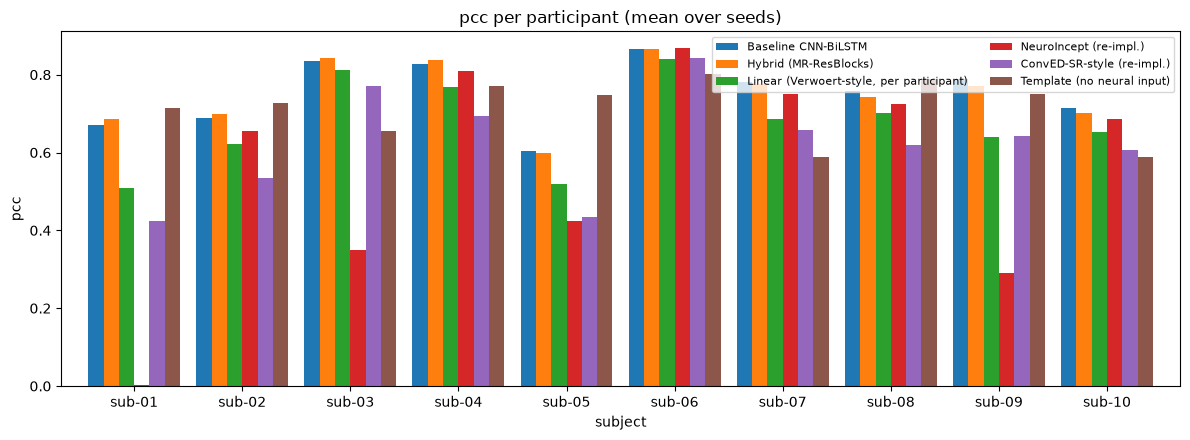

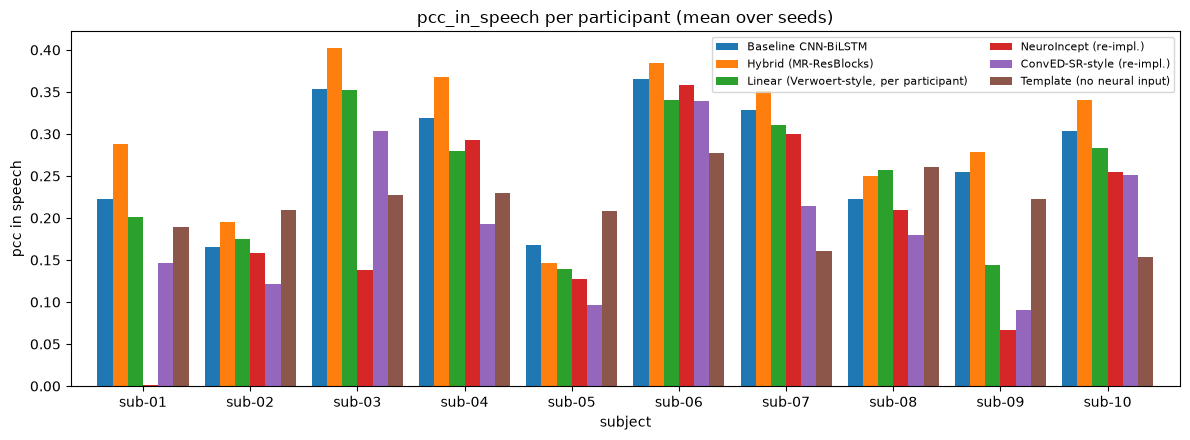

In [21]:
R.plot_subjects(dfb, "pcc"); R.plot_subjects(dfb, "pcc_in_speech")

## 5) Per fold (is one block driving a participant's value?)

In [11]:
dfb.pivot_table(index=["model","subject"], columns="fold", values="pcc").round(2)

fold                 0     1     2     3     4     5     6     7     8     9
model    subject                                                            
baseline sub-01   0.65  0.72  0.61  0.60  0.71  0.72  0.67  0.70  0.75  0.60
         sub-02   0.77  0.73  0.71  0.63  0.64  0.74  0.67  0.73  0.63  0.63
         sub-03   0.75  0.86  0.83  0.83  0.83  0.86  0.85  0.87  0.82  0.85
         sub-04   0.84  0.85  0.87  0.86  0.83  0.83  0.85  0.76  0.80  0.79
         sub-05   0.65  0.70  0.63  0.61  0.62  0.55  0.61  0.60  0.45  0.62
         sub-06   0.86  0.83  0.89  0.88  0.84  0.88  0.87  0.86  0.89  0.88
         sub-07   0.77  0.76  0.80  0.77  0.82  0.77  0.73  0.80  0.77  0.84
         sub-08   0.68  0.82  0.78  0.77  0.74  0.73  0.73  0.78  0.78  0.76
         sub-09   0.76  0.83  0.81  0.76  0.81  0.75  0.70  0.85  0.83  0.77
         sub-10   0.74  0.72  0.74  0.73  0.73  0.72  0.76  0.64  0.74  0.62
convedsr sub-01   0.24  0.51  0.35  0.36  0.48  0.44  0.42  0.44  0.56  0.44
         sub-02   0.60  0.55  0.50  0.43  0.52  0.56  0.57  0.65  0.47  0.50
         sub-03   0.70  0.69  0.82  0.72  0.78  0.79  0.79  0.85  0.78  0.79
         sub-04   0.70  0.60  0.74  0.76  0.71  0.73  0.66  0.62  0.75  0.67
         sub-05   0.39  0.53  0.45  0.37  0.46  0.41  0.36  0.45  0.44  0.48
         sub-06   0.80  0.81  0.86  0.86  0.85  0.82  0.86  0.86  0.86  0.84
         sub-07   0.64  0.73  0.71  0.66  0.71  0.56  0.59  0.53  0.68  0.75
         sub-08   0.61  0.69  0.58  0.57  0.71  0.55  0.60  0.65  0.67  0.57
         sub-09   0.63  0.62  0.60  0.62  0.65  0.69  0.55  0.68  0.70  0.68
         sub-10   0.67  0.66  0.60  0.62  0.56  0.61  0.64  0.56  0.61  0.51
hybrid   sub-01   0.57  0.75  0.60  0.62  0.78  0.71  0.72  0.70  0.74  0.69
         sub-02   0.74  0.77  0.70  0.60  0.67  0.77  0.65  0.75  0.66  0.65
         sub-03   0.76  0.84  0.81  0.85  0.85  0.88  0.85  0.86  0.86  0.86
         sub-04   0.83  0.84  0.87  0.88  0.83  0.85  0.87  0.80  0.82  0.79
         sub-05   0.63  0.64  0.65  0.58  0.69  0.68  0.61  0.56  0.40  0.54
         sub-06   0.85  0.82  0.89  0.88  0.86  0.86  0.87  0.87  0.89  0.89
         sub-07   0.72  0.74  0.75  0.73  0.87  0.75  0.82  0.82  0.78  0.78
         sub-08   0.70  0.82  0.76  0.78  0.72  0.71  0.70  0.77  0.76  0.71
         sub-09   0.80  0.74  0.78  0.76  0.81  0.76  0.70  0.82  0.77  0.78
         sub-10   0.75  0.73  0.74  0.70  0.68  0.72  0.73  0.64  0.72  0.59
linear   sub-01   0.40  0.56  0.40  0.45  0.60  0.51  0.56  0.48  0.58  0.58
         sub-02   0.64  0.60  0.59  0.52  0.58  0.68  0.62  0.69  0.69  0.60
         sub-03   0.71  0.82  0.79  0.82  0.81  0.83  0.84  0.84  0.81  0.83
         sub-04   0.77  0.77  0.80  0.80  0.78  0.79  0.77  0.69  0.73  0.76
         sub-05   0.55  0.56  0.61  0.51  0.60  0.48  0.47  0.49  0.45  0.48
         sub-06   0.81  0.84  0.85  0.85  0.82  0.83  0.84  0.85  0.86  0.86
         sub-07   0.72  0.72  0.63  0.72  0.76  0.70  0.43  0.71  0.68  0.75
         sub-08   0.67  0.74  0.72  0.73  0.73  0.66  0.66  0.73  0.72  0.67
         sub-09   0.68  0.69  0.67  0.59  0.67  0.58  0.52  0.72  0.66  0.62
         sub-10   0.71  0.67  0.70  0.66  0.63  0.69  0.63  0.64  0.68  0.52

In [22]:
import subprocess, sys, os
ROOT = r"C:\seeg_v2"
r = subprocess.run([sys.executable, "quality_metrics.py", "mcd"], cwd=ROOT,
                   env={**os.environ, "SEEG_OUT_DIR": os.environ["SEEG_OUT_DIR"]},
                   capture_output=True, text=True)
print(r.stdout); print(r.stderr[-1500:])

MCD: 660 entries written -> C:\seeg_v2\features_hifigan\quality\mcd_results.json

==== MCD in dB, LOWER = better | STAGE A (pooled, seed 42)

all test frames:
system   Baseline CNN-BiLSTM  ConvED-SR-style (re-impl.)  Hybrid (MR-ResBlocks)  Linear (Verwoert-style)  NeuroIncept (re-impl.)  Template (no neural input)
subject                                                                                                                                                     
sub-01                 35.45                       35.82                  34.54                    37.31                   35.65                       32.61
sub-02                 33.65                       36.54                  33.70                    36.81                   38.23                       31.72
sub-03                 31.84                       34.91                  29.38                    34.93                   33.22                       29.57
sub-04                 30.79                       33.92

In [23]:
import subprocess, sys, os, time
ROOT = r"C:\seeg_v2"
t0 = time.time()
r = subprocess.run([sys.executable, "quality_metrics.py", "stoiB", "folds=0", "sub-06"], cwd=ROOT,
                   env={**os.environ}, capture_output=True, text=True)
print(r.stdout[-3000:]); print(r.stderr[-1500:]); print(f"{time.time()-t0:.0f} s")

ystem better):
                                            comparison metric  n  mean_diff a_better_in  p_exact
       Hybrid (MR-ResBlocks) minus Baseline CNN-BiLSTM    mcd 10     -0.038        5/10   0.6953
   Hybrid (MR-ResBlocks) minus Linear (Verwoert-style)    mcd 10     -2.130       10/10   0.0020
Hybrid (MR-ResBlocks) minus ConvED-SR-style (re-impl.)    mcd 10     -2.628       10/10   0.0020
    Hybrid (MR-ResBlocks) minus NeuroIncept (re-impl.)    mcd 10     -2.440       10/10   0.0020
Hybrid (MR-ResBlocks) minus Template (no neural input)    mcd 10     -0.115        5/10   1.0000

paired (mcd_speech; negative difference = first system better):
                                            comparison     metric  n  mean_diff a_better_in  p_exact
       Hybrid (MR-ResBlocks) minus Baseline CNN-BiLSTM mcd_speech 10      0.304        3/10   0.2754
   Hybrid (MR-ResBlocks) minus Linear (Verwoert-style) mcd_speech 10     -1.768        9/10   0.0059
Hybrid (MR-ResBlocks) minus ConvED-

In [24]:
bat = os.path.join(ROOT, "run_quality.bat")
open(bat, "w").write("\n".join([
    "@echo off", f"cd /d {ROOT}", f"set SEEG_OUT_DIR={os.environ['SEEG_OUT_DIR']}",
    f'"{sys.executable}" quality_metrics.py stoiB folds=0 > quality_log.txt 2>&1']) + "\n")
subprocess.Popen(["cmd", "/c", bat], creationflags=0x00000008 | 0x00000200, close_fds=True)
print("started")

started


In [25]:
from IPython.display import Audio, display
import os
AUD = os.path.join(os.environ["SEEG_OUT_DIR"], "stageB_audio")
SUB = "sub-06"
order = [("original", "الصوت الأصلي"), ("truth", "HiFi-GAN من الـ mel الحقيقي (السقف)"),
         ("template", "Template (بلا إشارة عصبية)"), ("linear", "Linear"), ("baseline", "Baseline CNN-BiLSTM"),
         ("hybrid", "Hybrid (MR-ResBlocks)"), ("convedsr", "ConvED-SR-style"), ("neuroincept", "NeuroIncept")]
for s, name in order:
    p = os.path.join(AUD, f"{SUB}_fold0_{s}.wav")
    if os.path.exists(p):
        print(name); display(Audio(p))

الصوت الأصلي


HiFi-GAN من الـ mel الحقيقي (السقف)


Template (بلا إشارة عصبية)


Linear


Baseline CNN-BiLSTM


Hybrid (MR-ResBlocks)


ConvED-SR-style


NeuroIncept


In [26]:
dfb[dfb.model == "neuroincept"].pivot_table(index="subject", columns="fold", values="pcc").round(2)

fold,0,1,2,3,4,5,6,7,8,9
subject,,,,,,,,,,
sub-01,-0.00,-0.00,0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,0.03
sub-02,0.69,0.67,0.67,0.53,0.59,0.73,0.68,0.70,0.65,0.63
sub-03,0.01,0.84,0.03,0.02,0.84,0.00,0.02,0.06,0.83,0.86
sub-04,0.82,0.82,0.84,0.84,0.82,0.82,0.81,0.73,0.79,0.80
sub-05,0.60,0.02,0.03,0.05,0.66,0.63,0.54,0.62,0.48,0.59
sub-06,0.85,0.85,0.88,0.88,0.86,0.87,0.87,0.87,0.88,0.88
sub-07,0.73,0.73,0.79,0.71,0.80,0.72,0.70,0.78,0.74,0.81
sub-08,0.66,0.76,0.73,0.74,0.75,0.71,0.67,0.76,0.73,0.71
sub-09,0.64,0.01,-0.00,0.03,-0.00,0.00,0.66,0.80,0.75,0.00


In [27]:
import numpy as np
d = dfb.pivot_table(index=["subject", "fold"], columns="model", values="pcc")
ok = d["neuroincept"] >= 0.10                      # عتبة معلنة مسبقًا: PCC < 0.10 = تدريب منهار
print("collapsed participant-folds:", int((~ok).sum()), "of", len(d))
print(d.loc[ok, ["linear", "baseline", "hybrid", "neuroincept", "convedsr"]].mean().round(3))
print("\nper participant, collapsed folds (NeuroIncept):")
print((~ok).groupby(level="subject").sum())

collapsed participant-folds: 25 of 100
model
linear         0.694
baseline       0.760
hybrid         0.758
neuroincept    0.737
convedsr       0.642
dtype: float64

per participant, collapsed folds (NeuroIncept):
subject
sub-01    10
sub-02     0
sub-03     6
sub-04     0
sub-05     3
sub-06     0
sub-07     0
sub-08     0
sub-09     6
sub-10     0
Name: neuroincept, dtype: int64


In [28]:
import json, os, importlib, pandas as pd
import quality_metrics as Q, stageB_subject as B
importlib.reload(Q)
Q.run_mcd()                                   # يحدّث MCD ليشمل NeuroIncept (ثوانٍ)
dfb = B.load_runs_b()
mcd = pd.DataFrame(json.load(open(Q.JS_MCD)).values());  mcd = mcd[mcd.stage == "B"]
sto = pd.DataFrame(json.load(open(Q.JS_STOI)).values());  sto = sto[sto.stage == "B"]

def per_sub(df, col):                         # متوسط الـ folds ثم متوسط المشاركين
    return df.groupby(["system", "subject"])[col].mean().groupby("system").mean()

tab = pd.DataFrame({
    "PCC": dfb.groupby(["model", "subject"])["pcc"].mean().groupby("model").mean(),
    "PCC in speech": dfb.groupby(["model", "subject"])["pcc_in_speech"].mean().groupby("model").mean(),
    "Residual PCC": dfb.groupby(["model", "subject"])["residual_pcc"].mean().groupby("model").mean(),
    "MCD dB (lower=better)": per_sub(mcd, "mcd"),
    "MCD speech dB": per_sub(mcd, "mcd_speech"),
    "STOI": per_sub(sto, "stoi"), "eSTOI": per_sub(sto, "estoi")})
order = ["truth", "template", "linear", "baseline", "hybrid", "neuroincept", "convedsr"]
tab = tab.reindex([o for o in order if o in tab.index])
tab.index = [Q.LABEL.get(i, i) for i in tab.index]
pd.set_option("display.width", 220); print(tab.round(3).to_string())

MCD: 660 entries written -> C:\seeg_v2\features_hifigan\quality\mcd_results.json
                                  PCC  PCC in speech  Residual PCC  MCD dB (lower=better)  MCD speech dB   STOI  eSTOI
HiFi-GAN of true mel (ceiling)    NaN            NaN           NaN                    NaN            NaN  0.694  0.569
Template (no neural input)        NaN            NaN           NaN                 31.098         64.451  0.324 -0.012
Linear (Verwoert-style)         0.675          0.248         0.351                 33.112         64.460  0.339  0.004
Baseline CNN-BiLSTM             0.754          0.270         0.475                 31.020         62.388  0.399  0.015
Hybrid (MR-ResBlocks)           0.752          0.300         0.477                 30.982         62.692  0.383  0.025
NeuroIncept (re-impl.)          0.556          0.191         0.340                 33.422         67.486  0.400  0.001
ConvED-SR-style (re-impl.)      0.623          0.193         0.321                 33.

In [29]:
Q.summary()          # جداول MCD و STOI و eSTOI لكل مشارك، + اختبارات Hybrid مقابل الباقين لـ MCD


==== MCD in dB, LOWER = better | STAGE A (pooled, seed 42)

all test frames:
system   Baseline CNN-BiLSTM  ConvED-SR-style (re-impl.)  Hybrid (MR-ResBlocks)  Linear (Verwoert-style)  NeuroIncept (re-impl.)  Template (no neural input)
subject                                                                                                                                                     
sub-01                 35.45                       35.82                  34.54                    37.31                   35.65                       32.61
sub-02                 33.65                       36.54                  33.70                    36.81                   38.23                       31.72
sub-03                 31.84                       34.91                  29.38                    34.93                   33.22                       29.57
sub-04                 30.79                       33.92                  31.78                    36.37                   33.88         

In [30]:
sp = sto.groupby(["subject", "system"])[["stoi", "estoi"]].mean().reset_index()
rows = []
for met in ("stoi", "estoi"):
    for b in ("template", "baseline", "linear", "neuroincept", "convedsr"):
        r = Q._paired(sp, met, "hybrid", b)
        if r: rows.append(dict(metric=met, comparison=f"hybrid - {b}", n=r[0], mean_diff=round(r[1], 3),
                               hybrid_better_in=f"{r[2]}/{r[0]}", p_exact=round(r[3], 4)))
print(pd.DataFrame(rows).to_string(index=False))

metric           comparison  n  mean_diff hybrid_better_in  p_exact
  stoi    hybrid - template 10      0.058             9/10   0.0273
  stoi    hybrid - baseline 10     -0.016             2/10   0.0645
  stoi      hybrid - linear 10      0.043             8/10   0.0098
  stoi hybrid - neuroincept 10     -0.017             4/10   0.5566
  stoi    hybrid - convedsr 10      0.075            10/10   0.0020
 estoi    hybrid - template 10      0.037             7/10   0.0371
 estoi    hybrid - baseline 10      0.010             6/10   0.4316
 estoi      hybrid - linear 10      0.021             8/10   0.1602
 estoi hybrid - neuroincept 10      0.024             7/10   0.1602
 estoi    hybrid - convedsr 10      0.025             6/10   0.1934


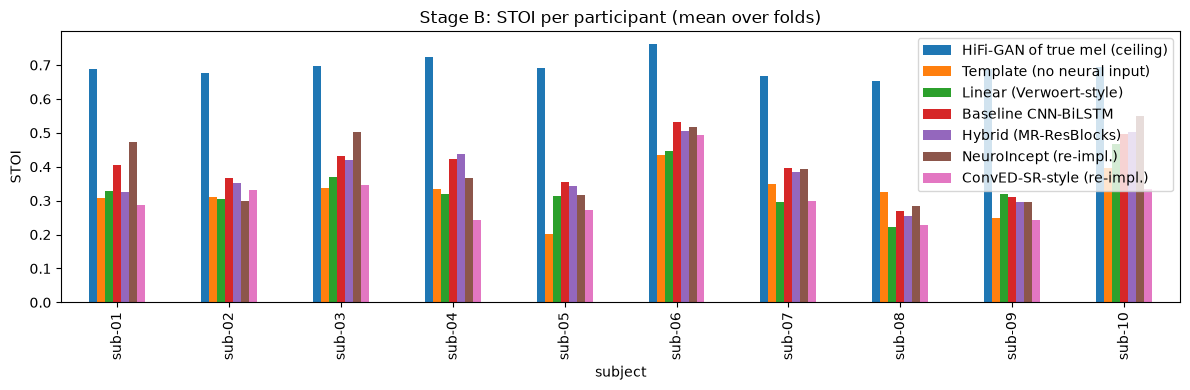

In [31]:
import matplotlib.pyplot as plt
p = sto.groupby(["subject", "system"])["stoi"].mean().unstack()[[c for c in order if c in set(sto.system)]]
p.columns = [Q.LABEL.get(c, c) for c in p.columns]
ax = p.plot(kind="bar", figsize=(12, 4)); ax.set_ylabel("STOI"); ax.set_title("Stage B: STOI per participant (mean over folds)")
plt.tight_layout(); plt.show()

In [32]:
x = dfb[["model", "subject", "fold", "pcc"]].rename(columns={"model": "system"}).merge(
    sto[["system", "subject", "fold", "stoi", "estoi"]], on=["system", "subject", "fold"])
x["collapsed"] = x["pcc"] < 0.10
print(x.groupby(["system", "collapsed"])[["pcc", "stoi", "estoi"]].mean().round(3))
print(x.groupby(["system", "collapsed"]).size().unstack(fill_value=0))
print("\ncorrelation PCC vs STOI / eSTOI across participant-folds:")
print(x.groupby("system").apply(lambda d: pd.Series({"PCC~STOI": d.pcc.corr(d.stoi), "PCC~eSTOI": d.pcc.corr(d.estoi)})).round(2))

                         pcc   stoi  estoi
system      collapsed                     
baseline    False      0.746  0.399  0.015
convedsr    False      0.598  0.308  0.000
hybrid      False      0.734  0.383  0.025
linear      False      0.667  0.339  0.004
neuroincept False      0.714  0.378 -0.001
            True       0.006  0.488  0.009
collapsed    False  True 
system                   
baseline        10      0
convedsr        10      0
hybrid          10      0
linear          10      0
neuroincept      8      2

correlation PCC vs STOI / eSTOI across participant-folds:
             PCC~STOI  PCC~eSTOI
system                          
baseline         0.51       0.62
convedsr         0.42       0.06
hybrid           0.53       0.67
linear           0.32       0.38
neuroincept     -0.32      -0.24


best participant: sub-06 (mean PCC 0.867); best fold: 2 (PCC 0.888)


C:\seeg_v2\.venv\Lib\site-packages\torch\nn\utils\weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


saved -> C:\seeg_v2\features_hifigan\paper_figures\fig_hybrid_sub-06_fold2_15s


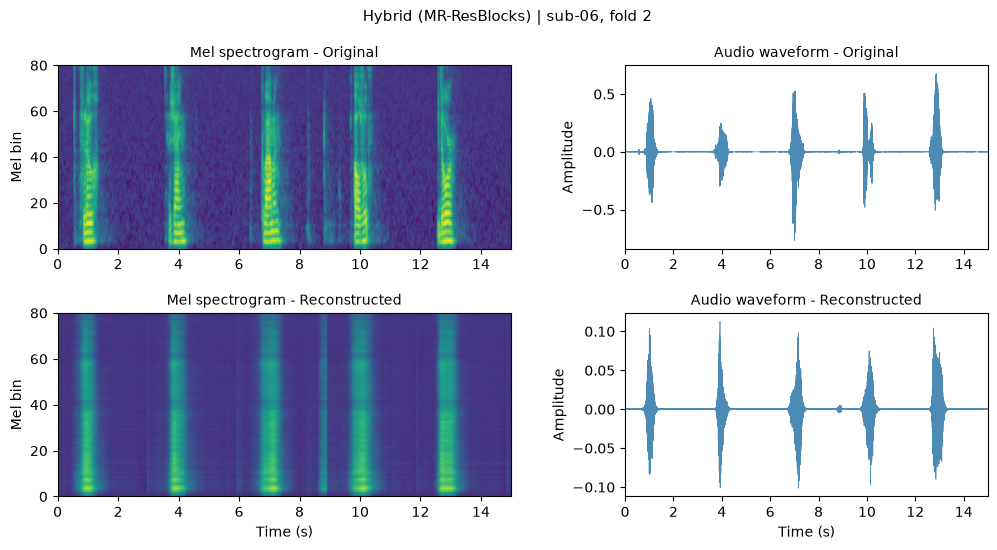

In [33]:
import os, glob, numpy as np, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.io import wavfile
import stageA_stoi as S, stageB_subject as B

OUT = os.environ["SEEG_OUT_DIR"]; SR, HOP = 22050, 256
MODEL, SEG_S = "hybrid", 15

# 1) أفضل مشارك (متوسط PCC عبر folds) ثم أفضل fold له
dfm = B.load_runs_b(); dfm = dfm[dfm.model == MODEL]
SUB = dfm.groupby("subject")["pcc"].mean().idxmax()
row = dfm[dfm.subject == SUB].loc[lambda d: d.pcc.idxmax()]
FOLD = int(row.fold)
print(f"best participant: {SUB} (mean PCC {dfm[dfm.subject == SUB].pcc.mean():.3f}); best fold: {FOLD} (PCC {row.pcc:.3f})")

# 2) التنبؤ المحفوظ + الـ mel الحقيقي + فك الترميز بـ HiFi-GAN
z = np.load(os.path.join(OUT, "stageB", f"{MODEL}_{SUB}_fold{FOLD}_preds.npz"))
idx, P = z[SUB + "_idx"], z[SUB + "_P"]
spec = np.load(os.path.join(OUT, f"{SUB}_spec.npy"))[idx]
a, b = S.runs_of(idx)[0]; b = min(b, a + int(SEG_S * SR / HOP))     # أول مقطع متصل من كتلة الاختبار
decode = S.get_vocoder(); y = decode(P[a:b])
sr, x = S.read_wav(glob.glob(os.path.join(OUT, f"{SUB}_audio_*.wav"))[0])
fr0, fr1 = int(idx[a]), int(idx[b - 1]) + 1
ref = x[fr0 * HOP: fr1 * HOP]; n = min(len(ref), len(y)); ref, y = ref[:n], y[:n]
vmin, vmax = min(spec.min(), P.min()), max(spec.max(), P.max()); T = (b - a) * HOP / SR

# 3) الرسم
fig = plt.figure(figsize=(12, 5.6)); gs = GridSpec(2, 2, width_ratios=[1.25, 1], hspace=0.35, wspace=0.28)
for r, (m, lab) in enumerate(((spec[a:b], "Original"), (P[a:b], "Reconstructed"))):
    ax = fig.add_subplot(gs[r, 0]); ax.imshow(m.T, origin="lower", aspect="auto", extent=[0, T, 0, 80], vmin=vmin, vmax=vmax)
    ax.set_ylabel("Mel bin"); ax.set_title(f"Mel spectrogram - {lab}", fontsize=10); ax.set_xlabel("Time (s)" if r else "")
    ax2 = fig.add_subplot(gs[r, 1]); ax2.plot(np.arange(n) / SR, (ref, y)[r], lw=0.5, color="#4C8BB5")
    ax2.set_xlim(0, T); ax2.set_ylabel("Amplitude"); ax2.set_title(f"Audio waveform - {lab}", fontsize=10); ax2.set_xlabel("Time (s)" if r else "")
fig.suptitle(f"Hybrid (MR-ResBlocks) | {SUB}, fold {FOLD}", fontsize=11)

# 4) الحفظ (PNG + PDF) وملفا الصوت للاستماع
FIG = os.path.join(OUT, "paper_figures"); os.makedirs(FIG, exist_ok=True)
name = f"fig_{MODEL}_{SUB}_fold{FOLD}_{SEG_S}s"
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(FIG, f"{name}.{ext}"), dpi=300, bbox_inches="tight")
wavfile.write(os.path.join(FIG, f"{name}_original.wav"), SR, (ref / np.abs(ref).max() * 0.9 * 32767).astype(np.int16))
wavfile.write(os.path.join(FIG, f"{name}_reconstructed.wav"), SR, (y / np.abs(y).max() * 0.9 * 32767).astype(np.int16))
print("saved ->", os.path.join(FIG, name)); plt.show()

Stage A | hybrid | lr 0.0001 | best participant: sub-06 (PCC 0.859)


C:\seeg_v2\.venv\Lib\site-packages\torch\nn\utils\weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


saved -> C:\seeg_v2\features_hifigan\paper_figures\figA_hybrid_pooled_sub-06_block0_15s


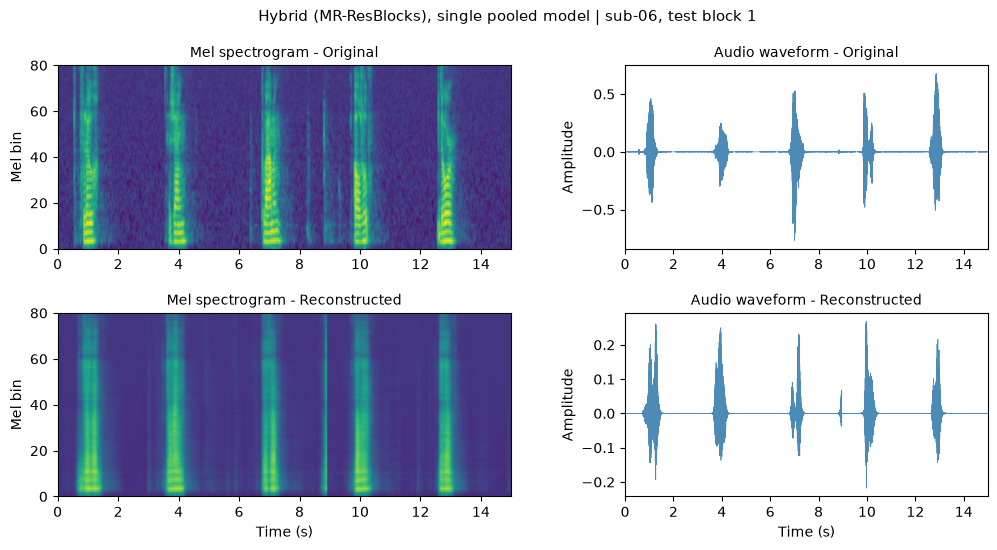

In [34]:
import os, glob, numpy as np, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.io import wavfile
import stageA_stoi as S, stageA_report as R

OUT = os.environ["SEEG_OUT_DIR"]; SR, HOP = 22050, 256
MODEL, SEG_S, RUN = "hybrid", 15, 0              # RUN: أي كتلة اختبار (0 أو 1، لكل مشارك كتلتان)

# 1) أفضل مشارك في Stage A: التنبؤات المحفوظة هي seed 42 بمعدل التعلم المختار
dfa = R.load_runs(); h = dfa[dfa.model == MODEL]
best_lr = float(h[h.seed != 42].lr.iloc[0])     # معدل التعلم المختار (seeds 123 و456 استعملاه)
h42 = h[(h.seed == 42) & np.isclose(h.lr, best_lr)]
SUB = h42.loc[h42.pcc.idxmax(), "subject"]
print(f"Stage A | {MODEL} | lr {best_lr:g} | best participant: {SUB} (PCC {h42.pcc.max():.3f})")

# 2) التنبؤ المحفوظ + الـ mel الحقيقي + فك الترميز
z = np.load(os.path.join(OUT, "stageA", f"{MODEL}_lr{best_lr:g}_seed42_preds.npz"))
idx, P = z[SUB + "_idx"], z[SUB + "_P"]
spec = np.load(os.path.join(OUT, f"{SUB}_spec.npy"))[idx]
a, b = S.runs_of(idx)[RUN]; b = min(b, a + int(SEG_S * SR / HOP))
decode = S.get_vocoder(); y = decode(P[a:b])
sr, x = S.read_wav(glob.glob(os.path.join(OUT, f"{SUB}_audio_*.wav"))[0])
fr0, fr1 = int(idx[a]), int(idx[b - 1]) + 1
ref = x[fr0 * HOP: fr1 * HOP]; n = min(len(ref), len(y)); ref, y = ref[:n], y[:n]
vmin, vmax = min(spec.min(), P.min()), max(spec.max(), P.max()); T = (b - a) * HOP / SR

# 3) الرسم
fig = plt.figure(figsize=(12, 5.6)); gs = GridSpec(2, 2, width_ratios=[1.25, 1], hspace=0.35, wspace=0.28)
for r, (m, lab) in enumerate(((spec[a:b], "Original"), (P[a:b], "Reconstructed"))):
    ax = fig.add_subplot(gs[r, 0]); ax.imshow(m.T, origin="lower", aspect="auto", extent=[0, T, 0, 80], vmin=vmin, vmax=vmax)
    ax.set_ylabel("Mel bin"); ax.set_title(f"Mel spectrogram - {lab}", fontsize=10); ax.set_xlabel("Time (s)" if r else "")
    ax2 = fig.add_subplot(gs[r, 1]); ax2.plot(np.arange(n) / SR, (ref, y)[r], lw=0.5, color="#4C8BB5")
    ax2.set_xlim(0, T); ax2.set_ylabel("Amplitude"); ax2.set_title(f"Audio waveform - {lab}", fontsize=10); ax2.set_xlabel("Time (s)" if r else "")
fig.suptitle(f"Hybrid (MR-ResBlocks), single pooled model | {SUB}, test block {RUN + 1}", fontsize=11)

# 4) الحفظ
FIG = os.path.join(OUT, "paper_figures"); os.makedirs(FIG, exist_ok=True)
name = f"figA_{MODEL}_pooled_{SUB}_block{RUN}_{SEG_S}s"
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(FIG, f"{name}.{ext}"), dpi=300, bbox_inches="tight")
wavfile.write(os.path.join(FIG, f"{name}_original.wav"), SR, (ref / np.abs(ref).max() * 0.9 * 32767).astype(np.int16))
wavfile.write(os.path.join(FIG, f"{name}_reconstructed.wav"), SR, (y / np.abs(y).max() * 0.9 * 32767).astype(np.int16))
print("saved ->", os.path.join(FIG, name)); plt.show()

In [1]:
import os, sys
ROOT = r"C:\seeg_v2"
os.environ["SEEG_OUT_DIR"] = os.path.join(ROOT, "features_hifigan")
sys.path.insert(0, ROOT)
import fig_eval_matrix as F
OUT = os.environ["SEEG_OUT_DIR"]
F.make(os.path.join(OUT, "stageB"), "fig_eval_matrix")

saved fig_eval_matrix | groups found: 50
participant-folds with PCC < 0.3 (below the PCC axis): {'convedsr': 1, 'neuroincept': 25}


In [1]:
import sys; sys.path.insert(0, r"C:\seeg_v2")
import fig_recon_pair as R
print(R.__file__)
print(hasattr(R, "get_decoder"))

C:\seeg_v2\fig_recon_pair.py
True


In [2]:
import os, sys, glob, numpy as np
ROOT = r"C:\seeg_v2"
os.environ["SEEG_OUT_DIR"] = os.path.join(ROOT, "features_hifigan")
sys.path.insert(0, ROOT)
import stageA_stoi as S, fig_recon_pair as R
OUT = os.environ["SEEG_OUT_DIR"]

sub, ranking = R.best_subject(os.path.join(OUT, "stageB"))
print("أفضل مشارك:", sub); print({k: round(v, 3) for k, v in sorted(ranking.items(), key=lambda kv: -kv[1])})

spec = np.load(os.path.join(OUT, f"{sub}_spec.npy"))
labels = np.load(os.path.join(OUT, f"{sub}_labels.npy"), allow_pickle=True)
sr, x = S.read_wav(glob.glob(os.path.join(OUT, f"{sub}_audio_*.wav"))[0])
decode = R.get_decoder(OUT)
R.make(sub, os.path.join(OUT, "stageB", f"hybrid_{sub}_fold2_preds.npz"), spec, x, decode,
       "fig_recon_stageB", title=f"{sub}, test block 3 (subject-dependent Hybrid)", labels=labels)

أفضل مشارك: sub-06
{'sub-06': 0.867, 'sub-03': 0.842, 'sub-04': 0.838, 'sub-07': 0.777, 'sub-09': 0.772, 'sub-08': 0.742, 'sub-10': 0.701, 'sub-02': 0.699, 'sub-01': 0.687, 'sub-05': 0.598}


C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\nn\utils\weight_norm.py:28: UserWarning: torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.
  warnings.warn("torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.")


saved fig_recon_stageB | sub-06 | seconds 15.0 | frames 1291


In [1]:
import os, glob
OUT = os.path.join(r"C:\seeg_v2", "features_hifigan")
for f in sorted(glob.glob(os.path.join(OUT, "stageA", "hybrid_*preds.npz"))):
    print(os.path.basename(f))

hybrid_lr0.0001_seed123_preds.npz
hybrid_lr0.0001_seed42_preds.npz
hybrid_lr0.0001_seed456_preds.npz
hybrid_null_lr0.0001_seed42_preds.npz


In [1]:
import os, sys, glob, numpy as np
ROOT = r"C:\seeg_v2"
os.environ["SEEG_OUT_DIR"] = os.path.join(ROOT, "features_hifigan")
sys.path.insert(0, ROOT)
import stageA_stoi as S, fig_recon_pair as R
OUT = os.environ["SEEG_OUT_DIR"]

sub, ranking = R.best_subject(os.path.join(OUT, "stageB"))
print("أفضل مشارك:", sub)

spec = np.load(os.path.join(OUT, f"{sub}_spec.npy"))
labels = np.load(os.path.join(OUT, f"{sub}_labels.npy"), allow_pickle=True)
sr, x = S.read_wav(glob.glob(os.path.join(OUT, f"{sub}_audio_*.wav"))[0])
decode = R.get_decoder(OUT)

R.make_both(sub,
            os.path.join(OUT, "stageA", "hybrid_lr0.0001_seed42_preds.npz"),
            os.path.join(OUT, "stageB", f"hybrid_{sub}_fold2_preds.npz"),
            spec, x, decode, "fig_recon_AB",
            title=f"{sub}, test block 3", labels=labels)

أفضل مشارك: sub-06


C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\nn\utils\weight_norm.py:28: UserWarning: torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.
  warnings.warn("torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.")


saved fig_recon_AB | sub-06 | seconds 15.0 | frames 1291


In [2]:
import os, sys
ROOT = r"C:\seeg_v2"
os.environ["SEEG_OUT_DIR"] = os.path.join(ROOT, "features_hifigan")
sys.path.insert(0, ROOT)
import fig_word_variability as W
OUT = os.environ["SEEG_OUT_DIR"]
W.make(OUT, "fig_word_variability")

Hybrid: words used 795 | within-participant r mean 0.316 (SD 0.208, n=10) | pooled r 0.270 | SD of predicted peaks / SD of original peaks 1.99
Template: words used 795 | within-participant r mean -0.089 (SD 0.123, n=10) | pooled r -0.038 | SD of predicted peaks / SD of original peaks 0.43
saved fig_word_variability | participants used: 10


In [1]:
import os, sys, numpy as np
ROOT = r"C:\seeg_v2"
os.environ["SEEG_OUT_DIR"] = os.path.join(ROOT, "features_hifigan")
sys.path.insert(0, ROOT)
import fig_word_variability as W
from scipy.stats import wilcoxon
OUT = os.environ["SEEG_OUT_DIR"]; FR = W.FR
rows = []
for s in W.SUBS:
    Y, P, T, pk = W.collect(OUT, s)
    if len(Y) < 5: continue
    sl = W.PK
    latY, latP = Y[:, sl].argmax(1) / FR, P[:, sl].argmax(1) / FR
    rows.append((s, len(Y), round(np.corrcoef(pk[:, 0], pk[:, 1])[0, 1], 2), round(np.corrcoef(latY, latP)[0, 1], 2)))
print("sub, عدد الكلمات, r السعة, r زمن الذروة")
for r in rows: print(r)
print("متوسط r السعة:", round(np.mean([r[2] for r in rows]), 2), "| Wilcoxon p:", wilcoxon([r[2] for r in rows]).pvalue)
print("متوسط r الزمن:", round(np.mean([r[3] for r in rows]), 2), "| Wilcoxon p:", wilcoxon([r[3] for r in rows]).pvalue)
W.make(OUT, "fig_word_variability")

sub, عدد الكلمات, r السعة, r زمن الذروة
('sub-01', 80, 0.21, 0.52)
('sub-02', 80, 0.1, 0.44)
('sub-03', 80, 0.77, 0.63)
('sub-04', 80, 0.36, 0.66)
('sub-05', 80, 0.52, 0.4)
('sub-06', 80, -0.03, 0.64)
('sub-07', 80, 0.33, 0.82)
('sub-08', 80, 0.3, 0.25)
('sub-09', 80, 0.24, 0.63)
('sub-10', 75, 0.34, 0.74)
متوسط r السعة: 0.31 | Wilcoxon p: 0.00390625
متوسط r الزمن: 0.57 | Wilcoxon p: 0.001953125
Hybrid: words used 795 | within-participant r mean 0.316 (SD 0.208, n=10) | pooled r 0.270 | SD of predicted peaks / SD of original peaks 1.99
Template: words used 795 | within-participant r mean -0.089 (SD 0.123, n=10) | pooled r -0.038 | SD of predicted peaks / SD of original peaks 0.43
saved fig_word_variability | participants used: 10


In [1]:
import os, sys
ROOT = r"C:\seeg_v2"
os.environ["SEEG_OUT_DIR"] = os.path.join(ROOT, "features_hifigan")
sys.path.insert(0, ROOT)
import fig_word_variability as W
print(W.__file__)
W.make(os.environ["SEEG_OUT_DIR"], "fig_word_variability")

C:\seeg_v2\fig_word_variability.py
sub, words, r amplitude, r latency
('sub-01', 80, 0.21, 0.52)
('sub-02', 80, 0.1, 0.44)
('sub-03', 80, 0.77, 0.63)
('sub-04', 80, 0.36, 0.66)
('sub-05', 80, 0.52, 0.4)
('sub-06', 80, -0.03, 0.64)
('sub-07', 80, 0.33, 0.82)
('sub-08', 80, 0.3, 0.25)
('sub-09', 80, 0.24, 0.63)
('sub-10', 75, 0.34, 0.74)
amplitude: mean r 0.316 | exact Wilcoxon p 0.0039 | template amplitude r -0.089
robustness (Spearman, mean over participants): amplitude 0.246 | latency 0.618 | words below amplitude axis: 90
latency  : mean r 0.572 | exact Wilcoxon p 0.0020 | words used 795
saved fig_word_variability | participants used: 10


In [2]:
import os, sys, numpy as np
ROOT = r"C:\seeg_v2"
os.environ["SEEG_OUT_DIR"] = os.path.join(ROOT, "features_hifigan")
sys.path.insert(0, ROOT)
import fig_word_variability as W
OUT = os.environ["SEEG_OUT_DIR"]; FR = W.FR; NW = W.nonword()

allw = []
print("sub | words | mean s/word | SD | min | max | total speech s | speech % of recording")
for s in W.SUBS:
    lab = np.asarray(np.load(os.path.join(OUT, f"{s}_labels.npy"), allow_pickle=True)).astype(str)
    isw = np.array([l not in NW for l in lab])
    # contiguous runs of the same word label = one word event
    d, starts = [], np.flatnonzero(isw & np.r_[True, lab[1:] != lab[:-1]])
    for st in starts:
        en = st
        while en < len(lab) and isw[en] and lab[en] == lab[st]: en += 1
        d.append((en - st) / FR)
    d = np.array(d); allw += list(d)
    print(s, len(d), round(d.mean(), 3), round(d.std(), 3), round(d.min(), 3), round(d.max(), 3),
          round(isw.sum() / FR, 1), round(100 * isw.mean(), 1))
allw = np.array(allw)
print(f"ALL: {len(allw)} words | mean {allw.mean():.3f} s | median {np.median(allw):.3f} | SD {allw.std():.3f} | range {allw.min():.2f}-{allw.max():.2f}")

sub | words | mean s/word | SD | min | max | total speech s | speech % of recording
sub-01 100 2.0 0.007 1.974 2.009 200.0 66.6
sub-02 100 2.001 0.006 1.974 2.009 200.1 66.6
sub-03 100 2.001 0.006 1.974 2.009 200.1 66.6
sub-04 100 2.001 0.006 1.974 2.009 200.1 66.7
sub-05 100 2.001 0.006 1.974 2.009 200.1 66.7
sub-06 100 2.001 0.007 1.974 2.02 200.1 66.6
sub-07 100 2.001 0.006 1.974 2.009 200.1 66.6
sub-08 100 2.001 0.007 1.974 2.009 200.1 66.6
sub-09 100 2.001 0.007 1.974 2.009 200.1 66.6
sub-10 95 2.004 0.006 1.974 2.009 190.4 66.8
ALL: 995 words | mean 2.001 s | median 1.997 | SD 0.006 | range 1.97-2.02


In [3]:
import os, sys, numpy as np
ROOT = r"C:\seeg_v2"
os.environ["SEEG_OUT_DIR"] = os.path.join(ROOT, "features_hifigan")
sys.path.insert(0, ROOT)
import fig_word_variability as W
import template_floor_continuous as T
OUT = os.environ["SEEG_OUT_DIR"]; FR = W.FR; NW = T.NONWORD

allw = []
print("sub | words | mean speech s per word window | SD | total speech s | speech % of recording | speech % of word windows")
for s in W.SUBS:
    spec = np.load(os.path.join(OUT, f"{s}_spec.npy"))
    lab = np.asarray(np.load(os.path.join(OUT, f"{s}_labels.npy"), allow_pickle=True)).astype(str)
    sp = T.speech_mask(spec)
    isw = np.array([l not in NW for l in lab])
    starts = np.flatnonzero(isw & np.r_[True, lab[1:] != lab[:-1]])
    d = []
    for st in starts:
        en = st
        while en < len(lab) and isw[en] and lab[en] == lab[st]: en += 1
        d.append(sp[st:en].sum() / FR)
    d = np.array(d); allw += list(d)
    print(s, len(d), round(d.mean(), 3), round(d.std(), 3), round(sp.sum() / FR, 1),
          round(100 * sp.mean(), 1), round(100 * sp[isw].mean(), 1))
allw = np.array(allw)
print(f"ALL: {len(allw)} words | mean {allw.mean():.3f} s | median {np.median(allw):.3f} | SD {allw.std():.3f} | range {allw.min():.2f}-{allw.max():.2f}")

sub | words | mean speech s per word window | SD | total speech s | speech % of recording | speech % of word windows
sub-01 100 0.633 0.159 65.4 21.8 31.6
sub-02 100 0.65 0.209 66.2 22.0 32.5
sub-03 100 0.651 0.196 70.0 23.3 32.6
sub-04 100 0.709 0.2 72.6 24.2 35.4
sub-05 100 0.741 0.221 75.7 25.2 37.0
sub-06 100 0.583 0.172 58.5 19.5 29.1
sub-07 100 0.476 0.175 50.5 16.8 23.8
sub-08 100 0.609 0.178 60.9 20.3 30.4
sub-09 100 0.563 0.174 56.6 18.9 28.1
sub-10 95 0.406 0.132 40.4 14.2 20.2
ALL: 995 words | mean 0.603 s | median 0.580 | SD 0.207 | range 0.00-1.37


In [4]:
import os, numpy as np
OUT = r"C:\seeg_v2\features_hifigan"
FR = 22050/256
for i in range(1, 11):
    s = f"sub-{i:02d}"
    ft = np.load(os.path.join(OUT, f"{s}_frame_times.npy"))
    ch = np.load(os.path.join(OUT, f"{s}_channels.npy"), allow_pickle=True)
    lab = np.load(os.path.join(OUT, f"{s}_labels.npy"), allow_pickle=True).astype(str)
    spec = np.load(os.path.join(OUT, f"{s}_spec.npy"))
    nw = [j for j in range(len(lab)) if lab[j] not in {"", "+", "nan", "None"} and (j == 0 or lab[j] != lab[j-1])]
    last = nw[-1]
    print(s, "| channels", len(ch), "| frames", len(lab), "| duration s", round(ft[-1], 1),
          "| word onsets", len(nw), "| last onset at s", round(last / FR, 1),
          "| mean mel energy last 15 s", round(spec[-int(15*FR):].mean(), 2), "| whole", round(spec.mean(), 2))

sub-01 | channels 127 | frames 25861 | duration s 300.3 | word onsets 100 | last onset at s 297.3 | mean mel energy last 15 s -8.52 | whole -8.46
sub-02 | channels 127 | frames 25862 | duration s 300.3 | word onsets 100 | last onset at s 297.3 | mean mel energy last 15 s -8.63 | whole -8.82
sub-03 | channels 127 | frames 25862 | duration s 300.3 | word onsets 100 | last onset at s 297.3 | mean mel energy last 15 s -8.61 | whole -8.56
sub-04 | channels 115 | frames 25862 | duration s 300.3 | word onsets 100 | last onset at s 297.3 | mean mel energy last 15 s -8.71 | whole -8.62
sub-05 | channels 60 | frames 25860 | duration s 300.3 | word onsets 100 | last onset at s 297.3 | mean mel energy last 15 s -8.54 | whole -8.65
sub-06 | channels 127 | frames 25868 | duration s 300.4 | word onsets 100 | last onset at s 297.4 | mean mel energy last 15 s -8.65 | whole -8.54
sub-07 | channels 127 | frames 25867 | duration s 300.3 | word onsets 100 | last onset at s 297.3 | mean mel energy last 15 s

In [6]:
import os
from pynwb import NWBHDF5IO
root = os.environ.get("SEEG_DATA_ROOT", r"C:/Users/USER/Desktop/courses/Conferences/Sevile/test/SingleWordProductionDutch-iBIDS")   # same folder used for extraction
for p in (9, 10):
    sub = f"sub-{p:02d}"
    io = NWBHDF5IO(os.path.join(root, sub, "ieeg", f"{sub}_task-wordProduction_ieeg.nwb"), "r"); nwb = io.read()
    n_eeg = nwb.acquisition["iEEG"].data.shape[0]; n_aud = nwb.acquisition["Audio"].data.shape[0]; n_stim = nwb.acquisition["Stimulus"].data.shape[0]
    print(sub, "| iEEG s", round(n_eeg / 1024, 1), "| audio s", round(n_aud / 48000, 1), "| stimulus s", round(n_stim / 48000, 1))
    io.close()

sub-09 | iEEG s 300.4 | audio s 300.4 | stimulus s 6.4
sub-10 | iEEG s 285.1 | audio s 285.1 | stimulus s 6.1


In [7]:
   exec(open(r"C:\seeg_v2\export_for_paper.py", encoding="utf-8").read())

Stage A rows: 170 | models: ['baseline', 'baseline_null', 'convedsr', 'convedsr_null', 'hybrid', 'hybrid_null', 'linear', 'neuroincept', 'neuroincept_null'] | seeds: [-1, 42, 123, 456]
Stage B rows: 500 | models: ['baseline', 'convedsr', 'hybrid', 'linear', 'neuroincept']
model
baseline       100
convedsr       100
hybrid         100
linear         100
neuroincept    100
copied stageA_stoi\stoi_results.json | top-level keys: ['sub-03|truth', 'sub-03|template', 'sub-03|hybrid', 'sub-06|truth', 'sub-06|template', 'sub-06|hybrid'] ...
copied quality\mcd_results.json | top-level keys: ['A|linear|sub-01|-', 'A|linear|sub-02|-', 'A|linear|sub-03|-', 'A|linear|sub-04|-', 'A|linear|sub-05|-', 'A|linear|sub-06|-'] ...
copied quality\stoiB_results.json | top-level keys: ['B|baseline|sub-06|0', 'B|convedsr|sub-06|0', 'B|hybrid|sub-06|0', 'B|template|sub-06|0', 'B|truth|sub-06|0', 'B|linear|sub-06|0'] ...
figures: ['fig_eval_matrix.pdf', 'fig_eval_matrix.png', 'fig_hybrid_sub-06_fold2_15s.pdf', 'f

In [9]:
# ===== STOI diagnostic (uses the LOCAL HiFi-GAN checkpoint: no download) =====
import os, sys, glob, numpy as np
from pystoi import stoi
sys.path.insert(0, r"C:\seeg_v2")
os.environ.setdefault("SEEG_OUT_DIR", OUT)             # OUT = your output folder variable
import stageA_stoi as S

def get_decoder_local(OUT):
    import torch
    from speechbrain.inference.vocoders import HIFIGAN
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    ck = os.path.join(OUT, "hifigan_ckpt"); kw = {}
    try:
        from speechbrain.utils.fetching import LocalStrategy
        kw["local_strategy"] = LocalStrategy.COPY
    except Exception:
        pass
    hifi = HIFIGAN.from_hparams(source=ck, savedir=ck, run_opts={"device": dev}, **kw)
    def decode(mel_t80):
        with torch.no_grad():
            m = torch.tensor(mel_t80.T, dtype=torch.float32)[None].to(dev)
            return hifi.decode_batch(m).squeeze().cpu().numpy()
    return decode

decode = get_decoder_local(OUT)
rng = np.random.default_rng(0)

def pcc_mean(y, p):
    return float(np.mean([np.corrcoef(y[:, b], p[:, b])[0, 1] if p[:, b].std() > 1e-9 else 0.0 for b in range(y.shape[1])]))

def score_mel(mel, idx, x):
    v, e = [], []
    for a, b in S.runs_of(idx):
        fr0, fr1 = int(idx[a]), int(idx[b - 1]) + 1
        y = decode(mel[a:b]); ref = x[fr0 * S.HOP: fr1 * S.HOP]; n = min(len(ref), len(y))
        v.append(stoi(ref[:n], y[:n], S.SR, extended=False)); e.append(stoi(ref[:n], y[:n], S.SR, extended=True))
    return float(np.mean(v)), float(np.mean(e))

print(f"{'sub':7s}{'system':38s}{'PCC':>7s}{'time-std':>10s}{'mean lvl':>10s}{'STOI':>8s}{'eSTOI':>8s}")
for sub in ["sub-01", "sub-03", "sub-06"]:
    spec = np.load(os.path.join(OUT, f"{sub}_spec.npy"))
    sr, x = S.read_wav(glob.glob(os.path.join(OUT, f"{sub}_audio_*.wav"))[0])
    P = {}
    for m in ["neuroincept", "hybrid"]:
        z = np.load(os.path.join(OUT, "stageB", f"{m}_{sub}_fold0_preds.npz"), allow_pickle=True)
        idx = z[sub + "_idx"]; P[m] = z[sub + "_P"]
    Y = spec[idx]; H = P["hybrid"]; N = P["neuroincept"]
    cands = {
        "NeuroIncept (real output)": N,
        "Hybrid (real output)": H,
        "CONTROL constant = Hybrid mean": np.tile(H.mean(0), (len(H), 1)),
        "CONTROL constant = NeuroIncept mean": np.tile(N.mean(0), (len(H), 1)),
        "CONTROL Hybrid frames shuffled": H[rng.permutation(len(H))],
        "CONTROL Gaussian noise (orig stats)": rng.normal(Y.mean(0), Y.std(0), Y.shape),
    }
    for name, mel in cands.items():
        s, e = score_mel(mel, idx, x)
        print(f"{sub:7s}{name:38s}{pcc_mean(Y, mel):7.3f}{mel.mean(1).std():10.3f}{mel.mean():10.2f}{s:8.3f}{e:8.3f}")
    print(f"{sub:7s}{'ORIGINAL (reference)':38s}{'':7s}{Y.mean(1).std():10.3f}{Y.mean():10.2f}")
    print("-" * 95)

C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\nn\utils\weight_norm.py:28: UserWarning: torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.
  warnings.warn("torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.")


sub    system                                    PCC  time-std  mean lvl    STOI   eSTOI
sub-01 NeuroIncept (real output)              -0.004     0.000     -8.47   0.474   0.013
sub-01 Hybrid (real output)                    0.567     1.207     -8.46   0.326  -0.036
sub-01 CONTROL constant = Hybrid mean            nan     0.000     -8.46   0.474   0.013
sub-01 CONTROL constant = NeuroIncept mean       nan     0.000     -8.47   0.474   0.013
sub-01 CONTROL Hybrid frames shuffled         -0.011     1.207     -8.46   0.186   0.018
sub-01 CONTROL Gaussian noise (orig stats)     0.002     0.213     -8.25   0.242  -0.000
sub-01 ORIGINAL (reference)                              1.657     -8.26
-----------------------------------------------------------------------------------------------
sub-03 NeuroIncept (real output)               0.119     0.000     -8.63   0.503   0.006
sub-03 Hybrid (real output)                    0.756     2.080     -7.88   0.421   0.013
sub-03 CONTROL constant = Hybr

In [10]:
#C:/seeg_v2/features_hifigan/
# ===== constant-output control for STOI/eSTOI (self-contained) =====
import os, sys, glob, json, numpy as np

OUT = r"C:/seeg_v2/features_hifigan"        # <-- EDIT: the folder that contains sub-01_spec.npy, stageB\, quality\, hifigan_ckpt\

# --- check the folder first ---
need = ["sub-01_spec.npy", "stageB", "quality", "hifigan_ckpt"]
for n in need:
    p = os.path.join(OUT, n)
    print(("OK      " if os.path.exists(p) else "MISSING ") + p)
assert os.path.exists(os.path.join(OUT, "sub-01_spec.npy")), "OUT is wrong: change the first line of this cell"

from pystoi import stoi
sys.path.insert(0, r"C:\seeg_v2")
os.environ["SEEG_OUT_DIR"] = OUT
import stageA_stoi as S

def get_decoder_local(OUT):
    import torch
    from speechbrain.inference.vocoders import HIFIGAN
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    ck = os.path.join(OUT, "hifigan_ckpt"); kw = {}
    try:
        from speechbrain.utils.fetching import LocalStrategy
        kw["local_strategy"] = LocalStrategy.COPY
    except Exception:
        pass
    hifi = HIFIGAN.from_hparams(source=ck, savedir=ck, run_opts={"device": dev}, **kw)
    def decode(mel_t80):
        with torch.no_grad():
            m = torch.tensor(mel_t80.T, dtype=torch.float32)[None].to(dev)
            return hifi.decode_batch(m).squeeze().cpu().numpy()
    return decode

decode = get_decoder_local(OUT)

def score_mel(mel, idx, x):
    v, e = [], []
    for a, b in S.runs_of(idx):
        fr0, fr1 = int(idx[a]), int(idx[b - 1]) + 1
        y = decode(mel[a:b]); ref = x[fr0 * S.HOP: fr1 * S.HOP]; n = min(len(ref), len(y))
        v.append(stoi(ref[:n], y[:n], S.SR, extended=False)); e.append(stoi(ref[:n], y[:n], S.SR, extended=True))
    return float(np.mean(v)), float(np.mean(e))

S_B = json.load(open(os.path.join(OUT, "quality", "stoiB_results.json")))
res = {}
print(f"\n{'sub':7s}{'CONSTANT':>10s}{'':8s}{'Hybrid':>10s}{'':8s}{'NeuroIncept':>12s}")
print(f"{'':7s}{'STOI':>10s}{'eSTOI':>8s}{'STOI':>10s}{'eSTOI':>8s}{'STOI':>12s}{'eSTOI':>8s}")
for sub in [f"sub-{i:02d}" for i in range(1, 11)]:
    spec = np.load(os.path.join(OUT, f"{sub}_spec.npy"))
    sr, x = S.read_wav(glob.glob(os.path.join(OUT, f"{sub}_audio_*.wav"))[0])
    z = np.load(os.path.join(OUT, "stageB", f"hybrid_{sub}_fold0_preds.npz"), allow_pickle=True)
    idx = z[sub + "_idx"]
    mask = np.ones(len(spec), bool); mask[idx] = False
    const = np.tile(spec[mask].mean(0), (len(idx), 1))          # mean log-mel of all NON-test frames
    s, e = score_mel(const, idx, x)
    res[sub] = dict(subject=sub, system="constant", fold=0, stoi=s, estoi=e)
    h = S_B[f"B|hybrid|{sub}|0"]; n = S_B[f"B|neuroincept|{sub}|0"]
    print(f"{sub:7s}{s:10.3f}{e:8.3f}{h['stoi']:10.3f}{h['estoi']:8.3f}{n['stoi']:12.3f}{n['estoi']:8.3f}")

print("\nMEAN over 10 participants: constant STOI %.3f | eSTOI %.3f" % (
    np.mean([r['stoi'] for r in res.values()]), np.mean([r['estoi'] for r in res.values()])))
outf = os.path.join(OUT, "quality", "stoiB_constant_control.json")
json.dump(res, open(outf, "w"), indent=1)
print("saved:", outf)

OK      C:/seeg_v2/features_hifigan\sub-01_spec.npy
OK      C:/seeg_v2/features_hifigan\stageB
OK      C:/seeg_v2/features_hifigan\quality
OK      C:/seeg_v2/features_hifigan\hifigan_ckpt

sub      CONSTANT            Hybrid         NeuroIncept
             STOI   eSTOI      STOI   eSTOI        STOI   eSTOI
sub-01      0.474   0.014     0.326  -0.036       0.474   0.013
sub-02      0.457  -0.012     0.352  -0.004       0.298  -0.003
sub-03      0.503   0.006     0.421   0.013       0.503   0.006
sub-04      0.472  -0.006     0.439   0.091       0.365  -0.006
sub-05      0.511   0.012     0.344  -0.002       0.316  -0.006
sub-06      0.542   0.007     0.505   0.039       0.517  -0.008
sub-07      0.538  -0.004     0.383   0.062       0.395   0.037
sub-08      0.469   0.006     0.255  -0.000       0.283   0.017
sub-09      0.507   0.024     0.297   0.013       0.297  -0.008
sub-10      0.550  -0.008     0.503   0.074       0.550  -0.030

MEAN over 10 participants: constant STOI 0.502 | e

In [11]:
# ===== Why does a CONSTANT spectrum score a high STOI? Two tests, 10 participants, Stage B fold index 0 =====
import os, sys, glob, numpy as np
OUT = r"C:/seeg_v2/features_hifigan"
from pystoi import stoi
sys.path.insert(0, r"C:\seeg_v2"); os.environ["SEEG_OUT_DIR"] = OUT
import stageA_stoi as S

def get_decoder_local(OUT):
    import torch
    from speechbrain.inference.vocoders import HIFIGAN
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    ck = os.path.join(OUT, "hifigan_ckpt"); kw = {}
    try:
        from speechbrain.utils.fetching import LocalStrategy
        kw["local_strategy"] = LocalStrategy.COPY
    except Exception:
        pass
    hifi = HIFIGAN.from_hparams(source=ck, savedir=ck, run_opts={"device": dev}, **kw)
    def decode(mel_t80):
        with torch.no_grad():
            m = torch.tensor(mel_t80.T, dtype=torch.float32)[None].to(dev)
            return hifi.decode_batch(m).squeeze().cpu().numpy()
    return decode
decode = get_decoder_local(OUT)

SUBS = [f"sub-{i:02d}" for i in range(1, 11)]
AUD = {s: S.read_wav(glob.glob(os.path.join(OUT, f"{s}_audio_*.wav"))[0])[1] for s in SUBS}
rows = []
print(f"{'sub':7s}{'const vs TRUE ref':>18s}{'vs SHIFTED ref':>16s}{'vs OTHER subj':>15s}{'level -1.15':>13s}{'level +1.15':>13s}")
for k, sub in enumerate(SUBS):
    spec = np.load(os.path.join(OUT, f"{sub}_spec.npy")); x = AUD[sub]
    other = AUD[SUBS[(k + 1) % 10]]
    z = np.load(os.path.join(OUT, "stageB", f"hybrid_{sub}_fold0_preds.npz"), allow_pickle=True)
    idx = z[sub + "_idx"]
    mask = np.ones(len(spec), bool); mask[idx] = False
    base = spec[mask].mean(0)
    out = []
    for shift_db in (0.0, None, None, -1.15, +1.15):
        pass
    vals = {"true": [], "shift": [], "other": [], "low": [], "high": []}
    for a, b in S.runs_of(idx):
        fr0, fr1 = int(idx[a]), int(idx[b - 1]) + 1
        ref = x[fr0 * S.HOP: fr1 * S.HOP]
        c = np.tile(base, (b - a, 1))
        y = decode(c); n = min(len(ref), len(y))
        vals["true"].append(stoi(ref[:n], y[:n], S.SR))
        ref_sh = np.roll(ref, int(10 * S.SR))[:n]                                  # same speech, shifted by 10 s
        vals["shift"].append(stoi(ref_sh, y[:n], S.SR))
        o = np.take(other, np.arange(fr0 * S.HOP, fr0 * S.HOP + n), mode="wrap")  # another participant's speech
        vals["other"].append(stoi(o, y[:n], S.SR))
        for key, g in (("low", -1.15), ("high", +1.15)):
            y2 = decode(c + g); n2 = min(len(ref), len(y2)); vals[key].append(stoi(ref[:n2], y2[:n2], S.SR))
    r = {key: float(np.mean(v)) for key, v in vals.items()}; rows.append(r)
    print(f"{sub:7s}{r['true']:18.3f}{r['shift']:16.3f}{r['other']:15.3f}{r['low']:13.3f}{r['high']:13.3f}")
m = {key: np.mean([r[key] for r in rows]) for key in rows[0]}
print("\nMEAN   " + "".join(f"{m[k]:>16.3f}" for k in ["true", "shift", "other", "low", "high"]))
print("(columns: true reference | reference shifted 10 s | another participant's speech | constant level -1.15 | constant level +1.15 in natural-log units)")

sub     const vs TRUE ref  vs SHIFTED ref  vs OTHER subj  level -1.15  level +1.15
sub-01              0.474           0.469          0.463        0.473        0.474
sub-02              0.457           0.454          0.506        0.456        0.458
sub-03              0.503           0.509          0.472        0.506        0.498
sub-04              0.472           0.468          0.512        0.475        0.472
sub-05              0.511           0.506          0.541        0.510        0.514
sub-06              0.542           0.540          0.539        0.542        0.539
sub-07              0.538           0.527          0.467        0.535        0.539
sub-08              0.469           0.472          0.504        0.467        0.469
sub-09              0.507           0.511          0.571        0.503        0.501
sub-10              0.550           0.553          0.479        0.561        0.554

MEAN              0.502           0.501           0.505           0.503           0.50

In [12]:
# ===== VERIFY: recompute the paper's numbers from the RAW result files (independent of my CSV and scripts) =====
import os, glob, json
import numpy as np, pandas as pd
from scipy.stats import wilcoxon
ROOT = r"C:\seeg_v2"
OUT = os.path.join(ROOT, "features_hifigan")

EXPECTED = {'NATemPccM': 0.744,
 'NATemInsM': 0.236,
 'NAHybPccM': 0.696,
 'NAHybInsM': 0.232,
 'NAHybResM': 0.369,
 'NAHybPccS': 0.004,
 'NABasPccM': 0.705,
 'NABasInsM': 0.219,
 'NAConPccM': 0.59,
 'NANeuPccM': 0.427,
 'NALinPccM': 0.472,
 'NANullHybPcc': 0.17,
 'NANullBasPcc': 0.044,
 'NAHBPccP': 0.322,
 'NAHBPccWin': 3.0,
 'NATHybPccP': 0.105,
 'NATHybInsP': 0.625,
 'NBTemPcc': 0.714,
 'NBTemIns': 0.214,
 'NBHybPcc': 0.752,
 'NBHybIns': 0.3,
 'NBHybRes': 0.477,
 'NBBasPcc': 0.754,
 'NBBasIns': 0.27,
 'NBLinPcc': 0.675,
 'NBConPcc': 0.623,
 'NBNeuPcc': 0.556,
 'NBHBasInsP': 0.006,
 'NBHBasInsWin': 9.0,
 'NBTHybInsP': 0.037,
 'NBTHybInsWin': 7.0,
 'NBNeuLow': 25.0,
 'NBConLow': 1.0,
 'NBHybBeatT': 62.0,
 'NBHybMin': 0.404,
 'NPvSHybPccA': 0.696,
 'NPvSHybPccB': 0.758,
 'NPvSHybPccP': 0.002,
 'NPvSHybPccWin': 10.0,
 'NPvSHybInsA': 0.232,
 'NPvSHybInsB': 0.287,
 'NPvSHybInsP': 0.064,
 'NPvSHybRatio': 92.0,
 'NAStoiCst': 0.512,
 'NBStoiCst': 0.502,
 'NAStoiTru': 0.718,
 'NAStoiHyb': 0.337,
 'NAStoiTem': 0.372,
 'NBStoiHyb': 0.383,
 'NBStoiTem': 0.324,
 'NBEstoiHyb': 0.025,
 'NAEstoiCst': -0.003,
 'NAMcdHyb': 31.5,
 'NBMcdHyb': 31.0}

# ---------- raw loading (own code) ----------
def load(dirname, stage_b=False):
    rows = []
    for p in sorted(glob.glob(os.path.join(OUT, dirname, "*.json"))):
        j = json.load(open(p))
        if "per_subject" not in j: continue
        if stage_b and "fold" not in j: continue
        for sub, r in j["per_subject"].items():
            rows.append(dict(model=j["model"], lr=j.get("lr", np.nan), seed=j.get("seed", -1), subject=sub, fold=j.get("fold", -1), **r))
    return pd.DataFrame(rows)

A = load("stageA"); B = load("stageB", stage_b=True)
LR = {"baseline": 1e-4, "hybrid": 1e-4, "neuroincept": 1e-3, "convedsr": 1e-3}
def selA(m):
    d = A[(A.model == m) & (A.lr.sub(LR[m]).abs() < 1e-9) & (A.seed.isin([42, 123, 456]))]
    return d
def seedmean(m, k):
    return selA(m).groupby("seed")[k].apply(lambda s: s.mean()).values       # mean over participants, per seed
def part(m, k):                                                            # per participant, mean over seeds
    return selA(m).groupby("subject")[k].mean().sort_index().values
lin = A[A.model == "linear"]
def W(x, y):
    d = np.asarray(x, float) - np.asarray(y, float)
    return float(wilcoxon(d).pvalue), int((d > 0).sum())

R = {}   # recomputed values
hybA = selA("hybrid")
R["NATemPccM"] = hybA.template_pcc.mean(); R["NATemInsM"] = hybA.template_in_speech.mean()
for tag, m in [("Hyb", "hybrid"), ("Bas", "baseline"), ("Con", "convedsr"), ("Neu", "neuroincept")]:
    R[f"NA{tag}PccM"] = seedmean(m, "pcc").mean()
R["NAHybInsM"] = seedmean("hybrid", "pcc_in_speech").mean(); R["NAHybResM"] = seedmean("hybrid", "residual_pcc").mean()
R["NAHybPccS"] = seedmean("hybrid", "pcc").std(ddof=1); R["NABasInsM"] = seedmean("baseline", "pcc_in_speech").mean()
R["NALinPccM"] = lin.pcc.mean()
R["NANullHybPcc"] = A[A.model == "hybrid_null"].pcc.mean(); R["NANullBasPcc"] = A[A.model == "baseline_null"].pcc.mean()
R["NAHBPccP"], R["NAHBPccWin"] = W(part("hybrid", "pcc"), part("baseline", "pcc"))
tp = hybA.groupby("subject")[["template_pcc", "template_in_speech"]].mean().sort_index()
R["NATHybPccP"], _ = W(part("hybrid", "pcc"), tp.template_pcc.values)
R["NATHybInsP"], _ = W(part("hybrid", "pcc_in_speech"), tp.template_in_speech.values)

hB = B[B.model == "hybrid"]
R["NBTemPcc"] = hB.template_pcc.mean(); R["NBTemIns"] = hB.template_in_speech.mean()
for tag, m in [("Hyb", "hybrid"), ("Bas", "baseline"), ("Lin", "linear"), ("Con", "convedsr"), ("Neu", "neuroincept")]:
    R[f"NB{tag}Pcc"] = B[B.model == m].pcc.mean()
R["NBHybIns"] = hB.pcc_in_speech.mean(); R["NBHybRes"] = hB.residual_pcc.mean(); R["NBBasIns"] = B[B.model == "baseline"].pcc_in_speech.mean()
R["NBNeuLow"] = int((B[B.model == "neuroincept"].pcc < 0.3).sum()); R["NBConLow"] = int((B[B.model == "convedsr"].pcc < 0.3).sum())
R["NBHybBeatT"] = int((hB.pcc > hB.template_pcc).sum()); R["NBHybMin"] = hB.pcc.min()
pB = lambda m, k: B[B.model == m].groupby("subject")[k].mean().sort_index().values
R["NBHBasInsP"], R["NBHBasInsWin"] = W(pB("hybrid", "pcc_in_speech"), pB("baseline", "pcc_in_speech"))
tB = hB.groupby("subject")[["template_in_speech"]].mean().sort_index()
R["NBTHybInsP"], R["NBTHybInsWin"] = W(pB("hybrid", "pcc_in_speech"), tB.template_in_speech.values)

# pooled (Stage A) vs subject-dependent (Stage B) on the SAME test blocks: Stage A TEST_B=(2,7) = Stage B folds 2 and 7
xa = {k: part("hybrid", k) for k in ["pcc", "pcc_in_speech"]}
xb = {k: B[(B.model == "hybrid") & (B.fold.isin([2, 7]))].groupby("subject")[k].mean().sort_index().values for k in ["pcc", "pcc_in_speech"]}
R["NPvSHybPccA"] = xa["pcc"].mean(); R["NPvSHybPccB"] = xb["pcc"].mean(); R["NPvSHybRatio"] = 100 * xa["pcc"].mean() / xb["pcc"].mean()
R["NPvSHybPccP"], R["NPvSHybPccWin"] = W(xb["pcc"], xa["pcc"])
R["NPvSHybInsA"] = xa["pcc_in_speech"].mean(); R["NPvSHybInsB"] = xb["pcc_in_speech"].mean(); R["NPvSHybInsP"], _ = W(xb["pcc_in_speech"], xa["pcc_in_speech"])

# ---------- audio files (raw) ----------
def find(name):
    hits = glob.glob(os.path.join(OUT, "**", name), recursive=True)
    return hits[0] if hits else None
def jl(name):
    p = find(name); print("  using", p) if p else print("  NOT FOUND:", name)
    return pd.DataFrame(json.load(open(p)).values()) if p else pd.DataFrame()
SA, SB, MC = jl("stoi_results.json"), jl("stoiB_results.json"), jl("mcd_results.json")
CA, CB = jl("stageA_constant_control.json"), jl("stoiB_constant_control.json")
sysm = lambda df, s, k="stoi": df[df.system == s][k].mean()
R["NAStoiTru"] = sysm(SA, "truth"); R["NAStoiHyb"] = sysm(SA, "hybrid"); R["NAStoiTem"] = sysm(SA, "template")
R["NBStoiHyb"] = sysm(SB, "hybrid"); R["NBStoiTem"] = sysm(SB, "template"); R["NBEstoiHyb"] = sysm(SB, "hybrid", "estoi")
if len(CA): R["NAStoiCst"] = CA.stoi.mean(); R["NAEstoiCst"] = CA.estoi.mean()
if len(CB): R["NBStoiCst"] = CB.stoi.mean()
if len(MC):
    mm = MC.groupby(["stage", "system", "subject"]).mcd.mean().reset_index().groupby(["stage", "system"]).mcd.mean()
    R["NAMcdHyb"] = mm[("A", "hybrid")]; R["NBMcdHyb"] = mm[("B", "hybrid")]

# ---------- compare ----------
print("raw rows: Stage A", len(A), "| Stage B", len(B), "| models A", sorted(A.model.unique()), "| models B", sorted(B.model.unique()))
print("\nStage B rows per (model, lr, seed) - expect 100 each:"); print(B.groupby(["model", B.lr.fillna(-1), "seed"]).size().to_string())
print("\nStage A rows per (model, lr, seed) - expect 10 each:"); print(A.groupby(["model", A.lr.fillna(-1), "seed"]).size().to_string())
bad = []; print(f"\n{'item':14s} {'paper':>9s} {'recomputed':>11s}  status")
for k, e in EXPECTED.items():
    if k not in R: print(f"{k:14s} {e:9.3f} {'--':>11s}  MISSING (file not found)"); bad.append(k); continue
    a = float(R[k]); tol = 0.051 if "Mcd" in k else (0.51 if k.endswith("Ratio") else 0.0006)
    ok = abs(a - e) <= tol
    print(f"{k:14s} {e:9.3f} {a:11.3f}  {'OK' if ok else '<<<<< DIFFERENT'}"); 
    if not ok: bad.append(k)
print(f"\n{len(EXPECTED) - len(bad)} of {len(EXPECTED)} match." + ("  ALL MATCH." if not bad else f"  Differences: {bad}"))

  using C:\seeg_v2\features_hifigan\stageA_stoi\stoi_results.json
  using C:\seeg_v2\features_hifigan\quality\stoiB_results.json
  using C:\seeg_v2\features_hifigan\quality\mcd_results.json
  using C:\seeg_v2\features_hifigan\quality\stageA_constant_control.json
  using C:\seeg_v2\features_hifigan\quality\stoiB_constant_control.json
raw rows: Stage A 170 | Stage B 500 | models A ['baseline', 'baseline_null', 'convedsr', 'convedsr_null', 'hybrid', 'hybrid_null', 'linear', 'neuroincept', 'neuroincept_null'] | models B ['baseline', 'convedsr', 'hybrid', 'linear', 'neuroincept']

Stage B rows per (model, lr, seed) - expect 100 each:
model        lr       seed
baseline      0.0001  42      100
convedsr      0.0010  42      100
hybrid        0.0001  42      100
linear       -1.0000  42      100
neuroincept   0.0001  42      100

Stage A rows per (model, lr, seed) - expect 10 each:
model             lr       seed
baseline           0.0001   42     10
                            123    10
    